# Persons Involved in the Group

The five students are:
- Elias Hasnaou
- Christian Trandafir
- Reda El Mekkaoui
- Mohamed Yazid Samrani
- Sefyani Diae

# Goal of this Practice

The goal is to study atmospheric heat waves in Brest (France) using statistical methods and recent machine learning approaches. First, the project will focus on historical data (1940-2025). Then, it will focus on the future (until 2100) under several CO2 emissions scenarios.

# Evaluation of this Practice

I will evaluate 3 main components:


1. the quality of the code (must be concise and well written)
2. the quality of the outputs (never forget that you are dealing with physical variables, so use the correct units)
3. the explanation of the method (describe mathematically the chosen approach, write directly into to notebook using Latex)
4. the discussion about your results (don't forget that data and results have a physical meaning)

# Import Libraries

- matplotlib (2D plotting)
- pylab (scientific computing)
- pandas (data structures and data analysis tools)
- torch (advanced machine learning)


In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

rng = np.random.default_rng(0)
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': .3})

# The ERA5 Database

Researchers use ECMWF’s ERA5 atmospheric reanalysis to examine surface air temperature (2-meter temperature) trends, seasonal variability, and extreme heat events in Brest, France. Because Brest is a coastal port city in Brittany, localized climate studies rely on ERA5's high hourly temporal resolution and continuous spatial coverage (9 km) to bridge gaps between land-based weather station observations and marine conditions. By integrating decades of historical assimilated data (from 1940 to the present), ERA5 allows climatologists to isolate long-term warming trends, model the Atlantic Ocean's moderating influence on local temperatures, and analyze how coastal mesoclimates respond to broader regional climate change.

# Part 1: Statistical Analysis of Atmospheric Heat Waves

In [2]:
# read data
daily_temp_brest = pd.read_csv('daily_temp_brest.csv')
print(daily_temp_brest)

       valid_time      mean
0      1940-01-01  3.484619
1      1940-01-02  2.409851
2      1940-01-03  6.619751
3      1940-01-04  7.831360
4      1940-01-05  8.317627
...           ...       ...
31407  2025-12-27  5.816040
31408  2025-12-28  5.751068
31409  2025-12-29  5.455261
31410  2025-12-30  5.287292
31411  2025-12-31  3.994019

[31412 rows x 2 columns]


Compute the seasonal cycle of the mean temperature in Brest. To do so, for each day of the year (between 1 and 365), compute the quantiles at 10%, 50%, and 90%. Apply a 1-month rolling mean to smooth the data. Plot the corresponding curves and comment on this figure.

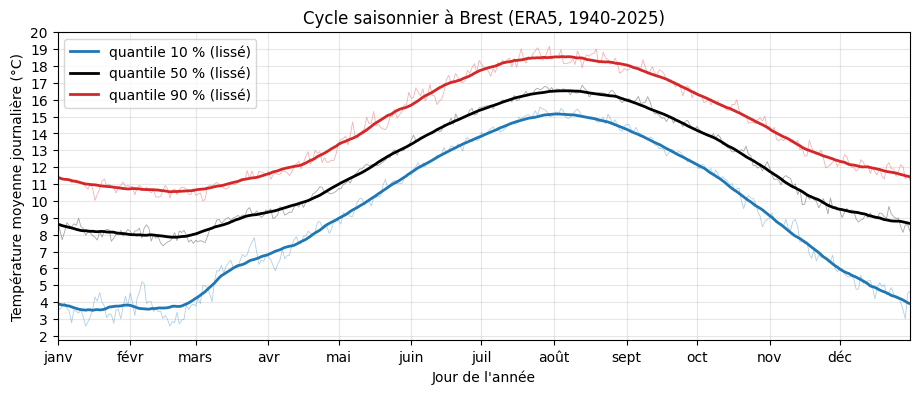

In [3]:
# on enlève les 29 février pour avoir 365 jours chaque année
d = daily_temp_brest.copy()
d['date'] = pd.to_datetime(d['valid_time'])
d = d[d['date'].dt.strftime('%m-%d') != '02-29']
d['jour'] = d.groupby(d['date'].dt.year).cumcount() + 1   # numéro du jour dans l'année (1 à 365)

# quantiles 10 %, 50 % et 90 % de la température pour chaque jour de l'année
q = pd.DataFrame({'q10': d.groupby('jour')['mean'].quantile(0.1),
                  'q50': d.groupby('jour')['mean'].quantile(0.5),
                  'q90': d.groupby('jour')['mean'].quantile(0.9)})

# moyenne glissante sur 31 jours ; comme l'année est un cycle, on colle fin décembre
# avant janvier et début janvier après décembre pour lisser aussi les bords
q_etendu = pd.concat([q.tail(15), q, q.head(15)])
qs = q_etendu.rolling(31, center=True).mean().iloc[15:-15]

# en fin : quantiles bruts ; en épais : quantiles lissés
for nom, couleur in [('q10', 'tab:blue'), ('q50', 'black'), ('q90', 'tab:red')]:
    plt.plot(q[nom], color=couleur, lw=0.6, alpha=0.35)
    plt.plot(qs[nom], color=couleur, lw=2, label=f'quantile {nom[1:]} % (lissé)')
plt.xlim(1, 365)
plt.xticks([1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335],
           ['janv', 'févr', 'mars', 'avr', 'mai', 'juin', 'juil', 'août', 'sept', 'oct', 'nov', 'déc'])
plt.yticks(range(2, 21))   # une graduation par °C pour lire les écarts entre courbes
plt.xlabel("Jour de l'année")
plt.ylabel('Température moyenne journalière (°C)')
plt.title('Cycle saisonnier à Brest (ERA5, 1940-2025)')
plt.legend()
plt.show()

**Commentaire.** Les trois courbes ont la même forme. La température est la plus basse vers le 19 février (quantile 50 %
à 7,8 °C) et la plus haute vers le 7 août (16,5 °C), donc environ 9 °C d'écart seulement entre l'hiver et l'été.

On pourrait s'attendre à ce que les jours les plus chauds soient autour du 21 juin, le jour où il y a le plus de soleil.
Pourtant le pic arrive vers le 7 août, environ 7 semaines plus tard, et le creux vers le 19 février au lieu du
21 décembre. On pense que c'est dû à la mer autour de Brest : elle se réchauffe et se refroidit lentement, donc l'air
suit le soleil avec du retard.

L'écart entre les quantiles 10 % et 90 % (entre la courbe bleue et la rouge) change selon la saison : environ 7,5 °C vers
le 10 janvier contre 3,4 °C fin juillet. Un même jour d'hiver peut donc être très doux ou très froid selon les années,
alors qu'en été les températures varient moins. La courbe à 90 % servira de seuil pour les vagues de chaleur.

Compute the duration and intensity of the different heat waves during the period 1940 to 2025. The duration corresponds to the number of consecutive days exceeding the 90% quantile. The intensity is defined as the mean temperature anomaly during those consecutive days.

In [4]:
DUREE_MIN = 3   # on garde les vagues d'au moins 3 jours chauds consécutifs

d = d.join(qs, on='jour')                # on ajoute à chaque jour les quantiles lissés de sa date
d['chaud'] = d['mean'] > d['q90']        # jour plus chaud que le quantile 90 % de sa date
d['anomalie'] = d['mean'] - d['q50']     # écart au quantile 50 % de sa date (°C)

# on numérote les suites de jours consécutifs : le numéro change à chaque passage chaud <-> pas chaud
d['suite'] = (d['chaud'] != d['chaud'].shift()).cumsum()

# chaque suite de jours chauds est une vague : durée = nombre de jours, intensité = anomalie moyenne
vagues = d[d['chaud']].groupby('suite').agg(debut=('date', 'first'),
                                            duree=('chaud', 'size'),
                                            intensite=('anomalie', 'mean'))
vagues = vagues[vagues['duree'] >= DUREE_MIN]
vagues['annee'] = vagues['debut'].dt.year

print(len(vagues), 'vagues de chaleur de 1940 à 2025')
print('\nLes plus longues :\n', vagues.nlargest(4, 'duree').round({'intensite': 2}).to_string(index=False))
print('\nLes plus intenses :\n', vagues.nlargest(4, 'intensite').round({'intensite': 2}).to_string(index=False))

421 vagues de chaleur de 1940 à 2025

Les plus longues :
      debut  duree  intensite  annee
1955-08-16     14       4.11   1955
1976-08-13     14       3.38   1976
1975-07-28     11       3.63   1975
1945-04-11     10       4.64   1945

Les plus intenses :
      debut  duree  intensite  annee
2022-07-16      3       7.69   2022
2000-06-16      3       6.69   2000
1976-06-25     10       6.51   1976
1940-06-03      6       6.10   1940


Un jour $d$ est **chaud** si $T_d>q_{90}(j_d)$, où $q_{90}(j)$ est le quantile 90 % lissé du jour de l'année $j$.
Une **vague de chaleur** est une suite de jours chauds consécutifs. Le sujet parle de « plusieurs jours », on a choisi
d'en garder au moins 3. Pour une vague $W$ :

$$\text{durée}=|W|\ \text{jours},\qquad \text{intensité}=\frac1{|W|}\sum_{d\in W}\big(T_d-q_{50}(j_d)\big)\ \text{en °C}.$$

L'intensité dit donc de combien de degrés la vague est, en moyenne, au-dessus de la normale de la date (le quantile 50 %).

**Commentaire.** On trouve 421 vagues en 86 ans, soit environ 5 par an. Les plus longues durent 14 jours (août 1955 et
août 1976). La plus intense est celle de **juillet 2022** : pendant 3 jours, il a fait en moyenne 7,7 °C de plus que la
normale pour cette date.

Une vague n'est pas forcément en été. Le seuil (le quantile 90 %) change avec la date : environ 11 °C en janvier et
18,5 °C en août. Par exemple, du 11 au 20 avril 1945, il a fait entre 12,6 et 17,4 °C pendant 10 jours : c'est très chaud
pour un mois d'avril, alors qu'en août ce seraient des jours plutôt frais.

Make the following scatter plot of the heat waves in Brest, with: x-axis representing duration, y-axis representing intensity, and the color representing the year of appearance. Comment on this figure.

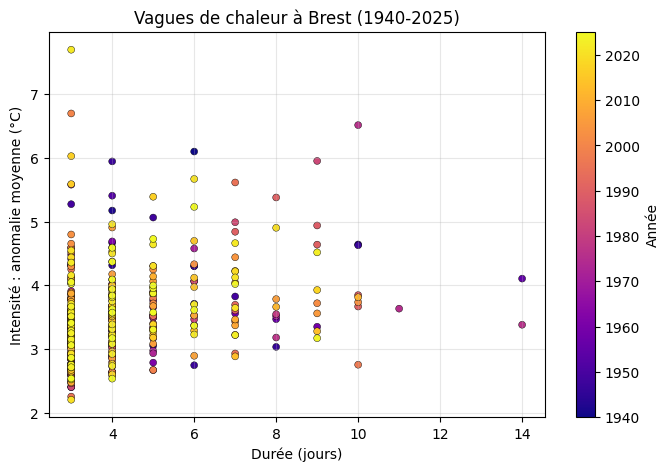

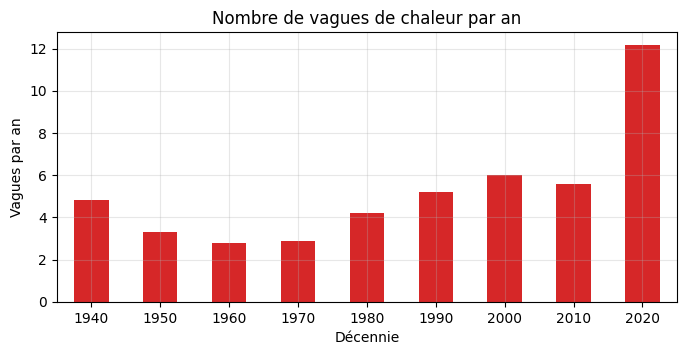

In [5]:
plt.figure(figsize=(8, 5))
plt.scatter(vagues['duree'], vagues['intensite'], c=vagues['annee'], cmap='plasma', s=25, edgecolor='k', lw=0.3)
plt.colorbar(label='Année')
plt.xlabel('Durée (jours)')
plt.ylabel('Intensité : anomalie moyenne (°C)')
plt.title('Vagues de chaleur à Brest (1940-2025)')
plt.show()

# nombre moyen de vagues par an dans chaque décennie (la décennie 2020 ne compte que 6 ans, de 2020 à 2025)
par_decennie = vagues.groupby(vagues['annee'] // 10 * 10).size()
nb_annees = pd.Series(10, index=par_decennie.index)
nb_annees[2020] = 6
(par_decennie / nb_annees).plot.bar(rot=0, color='tab:red', figsize=(8, 3.5))
plt.xlabel('Décennie')
plt.ylabel('Vagues par an')
plt.title('Nombre de vagues de chaleur par an')
plt.show()

**Commentaire.** La plupart des vagues sont courtes : environ 8 sur 10 durent 3 à 5 jours, et presque toutes ont une
intensité entre 2,5 et 5 °C. Le lien entre durée et intensité est faible : une vague longue n'est pas forcément plus
intense. Les vagues les plus intenses (plus de 5 °C) sont réparties sur toute la période, on ne voit pas de tendance
nette sur l'intensité.

Ce qui change vraiment, c'est le nombre de vagues (deuxième graphique) : environ 3 par an dans les années 1960-1970,
6 dans les années 2000, et 12 par an sur 2020-2025. Le seuil de 90 % est le même pour toutes les années, donc s'il y a
plus de vagues aujourd'hui, c'est que les températures ont augmenté.

# Part 2: Machine Learning Methods for the Prediction of Extreme Events in the Future

In [6]:
# read data
yearly_temp_brest = pd.read_csv('yearly_temp_brest.csv')
print(yearly_temp_brest)

    valid_time        max       min         co2
0   1940-01-01  24.790497 -3.994019  310.000000
1   1941-01-01  24.934845 -1.216583  311.162500
2   1942-01-01  25.541260 -1.027679  312.329359
3   1943-01-01  27.316742  1.669037  313.500594
4   1944-01-01  25.795715 -0.246552  314.676222
..         ...        ...       ...         ...
81  2021-01-01  28.604187 -1.346619  419.789832
82  2022-01-01  34.178619  1.063812  421.364044
83  2023-01-01  27.587494  0.408691  422.944159
84  2024-01-01  29.494080 -0.848175  424.530200
85  2025-01-01  27.788269  1.253174  428.501735

[86 rows x 4 columns]


Plot and comment on the maximum annual temperature in Brest from 1940 to 2025.

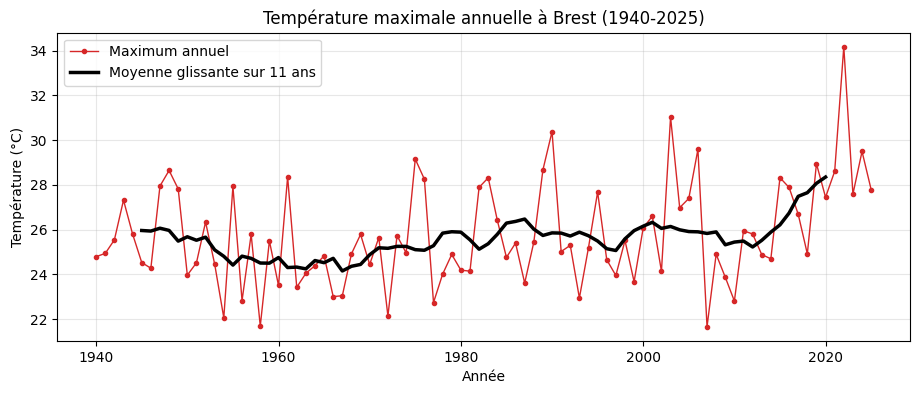

Moyenne 1940-1979 : 25.1 °C
Moyenne 1980-2025 : 26.3 °C


In [7]:
y = yearly_temp_brest.copy()
y['annee'] = pd.to_datetime(y['valid_time']).dt.year

plt.plot(y['annee'], y['max'], 'o-', ms=3, lw=1, color='tab:red', label='Maximum annuel')
# moyenne glissante sur 11 ans pour voir la tendance sans les variations d'une année à l'autre
plt.plot(y['annee'], y['max'].rolling(11, center=True).mean(), lw=2.5, color='k', label='Moyenne glissante sur 11 ans')
plt.xlabel('Année')
plt.ylabel('Température (°C)')
plt.title('Température maximale annuelle à Brest (1940-2025)')
plt.legend()
plt.show()

print('Moyenne 1940-1979 :', round(y.loc[y['annee'] < 1980, 'max'].mean(), 1), '°C')
print('Moyenne 1980-2025 :', round(y.loc[y['annee'] >= 1980, 'max'].mean(), 1), '°C')

**Commentaire.** Le maximum annuel varie beaucoup d'une année à l'autre : de 21,7 °C (1958 et 2007) à 34,2 °C (2022).
C'est normal, car il ne dépend que des quelques jours les plus chauds de l'année.

La moyenne sur 11 ans montre mieux la tendance. Elle baisse un peu entre les années 1940 et 1960 (de 26 à environ
24,5 °C), remonte vers 26 °C dans les années 1980, reste à peu près stable jusqu'en 2010, puis monte nettement jusqu'à
environ 28,4 °C autour de 2020. En moyenne, le maximum annuel vaut 25,1 °C sur 1940-1979 et 26,3 °C sur 1980-2025.
Le record de 2022 (34,2 °C) dépasse de plus de 3 °C le deuxième plus chaud (31,0 °C en 2003).

Compute the correlation between the maximum annual temperature in Brest and the global annual CO2. To increase the linear correlation coefficient, test several transformations of those two variables.

In [8]:
# transformations testées pour la température et pour le CO2
T = {'T': y['max'],
     'ln(T)': np.log(y['max']),
     'T lissée 5 ans': y['max'].rolling(5, center=True).mean(),
     'T lissée 11 ans': y['max'].rolling(11, center=True).mean(),
     'T lissée 21 ans': y['max'].rolling(21, center=True).mean()}
CO2 = {'CO2': y['co2'], 'ln(CO2)': np.log(y['co2']), 'CO2²': y['co2']**2}

# coefficient de corrélation linéaire pour chaque couple (température, CO2)
tableau = pd.DataFrame({c: {t: T[t].corr(CO2[c]) for t in T} for c in CO2})
print('Corrélation linéaire entre Tmax et CO2 (1940-2025) :')
print(tableau.round(2))

Corrélation linéaire entre Tmax et CO2 (1940-2025) :
                  CO2  ln(CO2)  CO2²
T                0.31     0.30  0.32
ln(T)            0.31     0.30  0.32
T lissée 5 ans   0.49     0.47  0.51
T lissée 11 ans  0.61     0.60  0.62
T lissée 21 ans  0.83     0.82  0.83


**Commentaire.** La corrélation entre Tmax et le CO2 est faible ($r = 0{,}31$) : d'une année à l'autre, Tmax varie
beaucoup, et le CO2 n'explique qu'une petite partie de ces variations.

Transformer les variables (ln, carré) ne change presque rien (entre 0,30 et 0,32). C'est logique : sur des intervalles
aussi petits (310 à 428 ppm, 21 à 34 °C), ces fonctions sont presque des droites.

Par contre, lisser la température augmente beaucoup la corrélation : 0,49 sur 5 ans, 0,61 sur 11 ans, 0,83 sur 21 ans.
La tendance de Tmax suit donc bien le CO2, mais pas la valeur d'une année précise. C'est pour ça qu'il faut des
prédictions probabilistes, et pas une seule valeur par année.

Use recent machine learning methods to provide probabilistic predictions (not deterministic) of maximum annual temperatures until 2100, conditionally on the three main climate scenarios. These SSPs differ in their level of annual CO2 emissions. Do not forget to present your approach mathematically and to justify your choice.

In [9]:
# read data
yearly_future_co2 = pd.read_csv('yearly_future_co2.csv')
print(yearly_future_co2)

    valid_time    ssp1-2.6    ssp2-4.5    ssp5-8.5
0   2026-01-01  420.780225  420.188542  421.121677
1   2027-01-01  421.558613  423.729506  425.754016
2   2028-01-01  422.333331  427.165818  430.437310
3   2029-01-01  423.102552  430.500572  435.172120
4   2030-01-01  423.864459  433.736770  439.959014
..         ...         ...         ...         ...
70  2096-01-01  405.235885  525.328317  905.708594
71  2097-01-01  403.933331  525.761931  915.671389
72  2098-01-01  402.625279  526.182729  925.743774
73  2099-01-01  401.313558  526.591091  935.926955
74  2100-01-01  400.000000  526.987384  946.222152

[75 rows x 4 columns]


## Notre démarche

Nous développons deux approches de prévision probabiliste : la **régression bayésienne** de Christian et la
**diffusion distributionnelle** d'Elias. La première représente l'incertitude sur la tendance et sur la
variabilité annuelle avec un modèle paramétrique. La seconde apprend la distribution des fluctuations
avec un réseau de neurones. On présente leurs équations, leur code et leurs projections sous les trois
scénarios, puis on discute leurs différences. Les autres propositions du groupe complètent la comparaison.

### Contributions et protocole

- **Christian** : régression bayésienne en logarithme du CO₂ ; l'incertitude porte sur la droite et le bruit annuel.
- **Elias** : DDPM, débruiteur stochastique au CRPS, pondération des extrêmes et bootstrap de l'ancre.
- **Reda** : loi GEV, adaptée aux maxima ; pour les minima, on applique la méthode aux températures opposées.
- **Yazid** : régression quantile, avec 99 quantiles et correction de leur ordre.
- **Diae** : réseau donnant les poids, moyennes et écarts-types d'un mélange de trois gaussiennes.

Le protocole commun utilise des validations chronologiques à l'intérieur de 1940–2000, puis un réajustement
sur 1940–2000 pour comparer les prédictions aux 25 années 2001–2025. L'ancre, la normalisation et les seuils
sont ajustés sur l'entraînement. La section diffusion détaille les trois découpages et les variantes.
Les résultats archivés du protocole commun sont les suivants :

| Méthode | CRPS validation Tmax | CRPS test Tmax | CRPS validation Tmin | CRPS test Tmin |
|:--|--:|--:|--:|--:|
| Référence : ancre log + gaussienne | 1,176 | 1,708 | 1,219 | 1,064 |
| Régression bayésienne | 1,169 | **1,580** | 1,217 | **0,980** |
| Diffusion D1, ancre fixe | 1,123 | 1,701 | **1,168** | 1,036 |
| Diffusion D3, ancre bootstrap | **1,114** | 1,650 | 1,174 | 0,989 |
| GEV (maxima / minima opposés) | 1,165 | 1,680 | 1,241 | 1,100 |
| Régression quantile régularisée | 1,137 | 1,799 | 1,196 | 1,030 |

Les scores sont en °C ; plus ils sont faibles, mieux c'est. Les réseaux de Diae ont été étudiés dans sa
contribution (CRPS test annoncé : 1,85 / 1,18 °C), mais n'ont pas été réévalués sur ces trois validations.
Ils ne participent donc pas au choix sur validation de ce tableau.

**D3 pour Tmax et D1 pour Tmin sont retenus sur validation.** Bayes a le meilleur CRPS observé sur le test
parmi ces méthodes, sans que cela justifie de refaire le choix après lecture du test. Le test avait déjà été
consulté dans le groupe : sa comparaison est rétrospective. Les petites différences ne suffisent pas à prouver
qu'un modèle sera meilleur sur de nouvelles années.

### Pourquoi le CRPS ?

Une prévision probabiliste donne une distribution $F$, et non une valeur unique. Le CRPS la compare à
l'observation $y$ :

$$\mathrm{CRPS}(F,y)=\mathbb E|X-y|-\frac12\mathbb E|X-X'|,$$

où $X$ et $X'$ sont deux tirages indépendants de $F$. Le premier terme pénalise l'éloignement à l'observation ;
le second tient compte de la dispersion. L'ensemble du score encourage une distribution correctement placée
et dispersée. On calcule ce score pour chaque année, puis on prend la moyenne. Il est en °C.
Une prévision déterministe redonne l'erreur absolue. Les 10 000 tirages décrivent la loi prédite ; ils ne
remplacent pas les 25 années de test. On complète le CRPS par un score de queue et la couverture des intervalles.

## La régression bayésienne

**Notations.** $T_t$ est le Tmax de l'année $t$ (°C), $x_t=\ln(C_t)$ où $C_t$ est le CO2 de l'année (ppm), et
$T=(T_{1940},\dots,T_{2025})$ la liste des $n=86$ valeurs observées. Le signe « $\mid$ » se lit « sachant » et
« $\sim$ » se lit « suit la loi ».

**Le modèle.** Tmax est une droite en $\ln(\mathrm{CO_2})$ plus un bruit, qui représente la météo de l'année :
$$T_t=a+b\,x_t+\sigma\,\varepsilon_t,\qquad \varepsilon_t\sim\mathcal N(0,1)\ \text{indépendants}.$$
$a$ est la hauteur de la droite, $b$ sa pente, et $\sigma$ l'écart-type du bruit (de combien une année s'écarte en
général de la droite).

**Pourquoi $\ln(\mathrm{CO_2})$ ?** À la question précédente, CO2, $\ln(\mathrm{CO_2})$ et CO2² avaient la même corrélation
(0,30 à 0,32). Mais en 2100 avec SSP5-8.5 (946 ppm), une simple droite donne un Tmax moyen d'environ 33 °C avec
$\ln(\mathrm{CO_2})$, 38 °C avec CO2 et 48 °C avec CO2². On garde $\ln(\mathrm{CO_2})$ : l'effet du CO2 sur la température
est souvent représenté par un forçage radiatif logarithmique. Cela motive cette ancre parcimonieuse,
mais ne démontre pas que les extrêmes locaux suivent exactement cette loi. La sensibilité au choix de l'ancre
est une limite des projections.

**Pourquoi bayésien ?** Avec 86 années, on ne connaît pas $a$, $b$ et $\sigma$ exactement : la pente estimée vaut
environ $7{,}4 \pm 2{,}5$. Sur les CO2 observés, ça change peu de chose, mais à 946 ppm une petite erreur sur la pente
devient une grosse erreur sur la température. Au lieu de garder une seule droite (celle des moindres carrés), on met
une **loi de probabilité sur les paramètres**, qui dit quelles valeurs de $(a,b,\sigma)$ sont plausibles, et on en
tire **beaucoup**. On part d'un a priori non informatif, avec une seule contrainte : plus de CO2 ne refroidit pas.
$$p(a,b,\sigma^2)\propto\sigma^{-2}\,\mathbf 1_{b\ge0}.$$

**La loi a posteriori** (ce qu'on sait des paramètres après avoir vu les données). On note $X$ le tableau des données
(une colonne de 1 et une colonne $x_t$), $\hat\beta=(\hat a,\hat b)=(X^\top X)^{-1}X^\top T$ la droite des moindres carrés,
et $\mathrm{MSE}=\frac1n\sum_t(T_t-\hat a-\hat b\,x_t)^2$ l'erreur quadratique moyenne de cette droite. Avant le rejet des pentes négatives,
on utilise le résultat classique du modèle linéaire gaussien :
$$\sigma^2\mid T\sim\frac{n\cdot\mathrm{MSE}}{\chi^2_{n-2}},\qquad (a,b)\mid\sigma^2,T\sim\mathcal N\big(\hat\beta,\ \sigma^2(X^\top X)^{-1}\big).$$
Le $\chi^2_{n-2}$ vient du fait que la somme des carrés des écarts, divisée par $\sigma^2$, est une somme de carrés de
lois normales ($n-2$ car on a estimé deux paramètres, $a$ et $b$). Pour tirer $(a,b,\sigma)$ ensemble, on tire d'abord
$\sigma^2$, puis $(a,b)$ sachant ce $\sigma^2$ : c'est la règle $p(a,b,\sigma^2)=p(\sigma^2)\,p(a,b\mid\sigma^2)$. Enfin,
on rejette les tirages où $b<0$.

**Prédiction par Monte-Carlo.** Pour une année future de CO2 $C$, on tire $N=10\,000$ jeux $(a^{(k)},b^{(k)},\sigma^{(k)})$
et, pour chacun, **une** température :
$$T^{(k)}=a^{(k)}+b^{(k)}\ln C+\sigma^{(k)}z^{(k)},\qquad z^{(k)}\sim\mathcal N(0,1).$$
Exemple avec trois vrais tirages pour 2100 et SSP5-8.5 ($\ln C = 6{,}85$) :

| $k$ | $\sigma$ | $a$ | $b$ | droite en 2100 | bruit $z$ | Tmax 2100 |
|:-:|:-:|:-:|:-:|:-:|:-:|:-:|
| 1 | 1,89 | −12,5 | 6,47 | 31,8 °C | −0,45 | 31,0 °C |
| 2 | 2,23 | −21,4 | 7,97 | 33,2 °C | +3,32 | 40,6 °C |
| 3 | 2,16 | −22,1 | 8,08 | 33,3 °C | −1,06 | 31,1 °C |

Les 10 000 valeurs de la dernière colonne forment la loi de Tmax en 2100, et $P(\text{Tmax}>40\,°\text{C})$ est la part
de tirages au-dessus de 40 °C. La loi contient deux hasards : la météo de l'année ($\sigma z$), et notre incertitude sur
la droite, qui change à chaque tirage grâce au bayésien. Sans le bayésien, la droite en 2100 vaudrait toujours
32,8 °C, la loi serait plus étroite et la probabilité de dépasser 40 °C tomberait d'environ 1,6 % à 0,05 %.

In [10]:
N = 10_000                          # nombre de tirages Monte-Carlo par année
x = np.log(y['co2'].to_numpy())     # variable explicative : ln(CO2)

def ajuster(x, t):
    # tout ce qu'il faut pour tirer dans la loi a posteriori de (a, b, sigma)
    X = np.c_[np.ones_like(x), x]
    V = np.linalg.inv(X.T @ X)
    beta = V @ X.T @ t                       # moindres carrés
    mse = np.mean((t - X @ beta) ** 2)        # erreur quadratique moyenne de la droite
    return beta, V, mse, len(t)

def tirer(modele, x_futur, n=N, seed=0):
    rng = np.random.default_rng(seed)
    # n tirages de la température pour chaque valeur de x_futur : tableau (n, nombre d'années)
    beta, V, mse, n_annees = modele
    params = np.empty((0, 3))
    while len(params) < n:                   # on tire jusqu'à avoir n jeux de paramètres avec b >= 0
        s = np.sqrt(n_annees * mse / rng.chisquare(n_annees - 2, n))      # sigma (loi du chi2)
        ab = beta + s[:, None] * rng.standard_normal((n, 2)) @ np.linalg.cholesky(V).T   # (a, b) sachant sigma
        garder = ab[:, 1] >= 0               # rejet : plus de CO2 ne refroidit pas
        params = np.vstack([params, np.c_[ab[garder], s[garder]]])
    a, b, s = params[:n].T
    return a[:, None] + b[:, None] * x_futur + s[:, None] * rng.standard_normal((n, len(x_futur)))

def crps(tirages, obs):
    # CRPS moyen (°C) entre les tirages (n, nombre d'années) et les valeurs observées
    s = np.sort(tirages, axis=0)
    n = len(s)
    w = (2 * np.arange(1, n + 1) - n - 1) / n**2
    return np.mean(np.abs(s - obs).mean(axis=0) - w @ s)

In [11]:
# on refait le test du groupe : appris sur 1940-2000, noté sur 2001-2025
avant, apres = (y['annee'] <= 2000).to_numpy(), (y['annee'] > 2000).to_numpy()
for var in ['max', 'min']:
    m = ajuster(x[avant], y[var].to_numpy()[avant])
    print(f'CRPS T{var} 2001-2025 : {crps(tirer(m, x[apres]), y[var].to_numpy()[apres]):.2f} °C')

CRPS Tmax 2001-2025 : 1.57 °C
CRPS Tmin 2001-2025 : 0.97 °C


Ces scores sont recalculés avec de nouveaux tirages. Les derniers centièmes peuvent différer des résultats archivés.
On garde les deux tableaux distincts : la validation a servi aux choix ; le test décrit les performances observées
sur 2001–2025, après ces choix.

## La diffusion distributionnelle

**Notations.** On reprend $T_t$ (température annuelle, °C) et $C_t$ (CO₂, ppm). L'échelle $e$ est
l'écart-type des résidus de la droite, calculé sur l'entraînement. Le résidu réduit $z_t$ est sans unité.

**Le modèle.** On conserve la même tendance logarithmique, mais le réseau apprend la distribution des fluctuations :

$$T_t=a+b\ln C_t+e\,z_t,\qquad z_t=\frac{T_t-a-b\ln C_t}{e}.$$

Le CO₂ agit par l'ancre $(a,b)$, ajustée avec $b\geq0$. Le réseau ne reçoit pas directement le CO₂ :
on suppose que la distribution des fluctuations reste stable dans le futur.

**Pourquoi une diffusion ?** Une régression quadratique apprend surtout une moyenne. Ici, on cherche à générer
une distribution, dont la forme n'est pas imposée gaussienne. On entraîne un débruiteur stochastique à différents
niveaux de bruit, suivant les diffusions distributionnelles de
[De Bortoli et al. (2025)](https://proceedings.mlr.press/v267/de-bortoli25b.html) et
[Park et al. (2026, prépublication)](https://arxiv.org/abs/2609.38632).

**L'apprentissage.** Un résidu historique $z$ est mélangé à un bruit indépendant :

$$u=(1-s)z+s\varepsilon,\qquad s\sim\mathcal U(0,1),\quad\varepsilon\sim\mathcal N(0,1).$$

Le réseau propose $M=32$ résidus $\widehat z_m=g_\phi(u,s,\zeta_m)$, avec des $\zeta_m\sim\mathcal N(0,1)$
indépendants. Les propositions partagent le même $(u,s)$. On minimise leur CRPS face au vrai résidu,
après retour aux °C. L'estimateur d'entraînement mélange 95 % de CRPS *fair* et 5 % de CRPS empirique
(*almost fair*, [Lang et al., 2024](https://arxiv.org/abs/2412.15832)). L'architecture est un MLP
$3\to32\to32\to1$, avec activations SiLU, soit **1 217 paramètres**.

**Prédiction par Monte-Carlo.** Pour prédire, on prend $s=1$ : le réseau reçoit du bruit pur et produit un résidu
en un passage. La variante D3 ajoute l'incertitude de l'ancre : on rééchantillonne les résidus par blocs de trois
années, à CO₂ fixé, puis on réajuste 500 droites. Un tirage s'écrit :

$$T_t^{(k)}=a^{(k)}+b^{(k)}\ln C_t+e\,g_\phi(\varepsilon_t^{(k)},1,\zeta_t^{(k)}).$$

Une trajectoire conserve sa droite et son réseau, avec de nouveaux bruits chaque année. Le bootstrap ne
réajuste pas le réseau : il représente seulement l'incertitude sur la tendance.

**Variantes.** On compare quatre versions du même débruiteur :

| Variante | Coût d'apprentissage | Ancre |
|:--|:--|:--|
| D1 | CRPS | Fixe |
| D2 | CRPS + $0{,}5\,\mathrm{twCRPS}$ | Fixe |
| D3 | CRPS | Bootstrap |
| D4 | CRPS + $0{,}5\,\mathrm{twCRPS}$ | Bootstrap |

Le twCRPS est le CRPS après transformation $v(x)=\max(x,h)$ pour Tmax, ou $\min(x,h)$ pour Tmin.
Le seuil $h$ est le quantile 80 % / 20 % calculé sur l'entraînement. Toutes les années contribuent.
Cette pondération cible les extrêmes ; le CRPS global reste le critère principal.



**Validation.** On entraîne jusqu'en 1970, 1980 et 1990, puis on valide sur les dix années suivantes,
avec trois graines (0, 1, 2). L'ancre, l'échelle et les seuils sont réajustés dans chaque entraînement.
La sélection enregistrée est D3 pour Tmax et D1 pour Tmin ; les résultats communs figurent dans le tableau précédent.

Deux essais supplémentaires sont conservés dans les expériences détaillées : C0, générateur sans débruitage,
et un DDPM classique. Ce dernier a été écarté après des Tmin allant jusqu'à −1 933 °C dans la configuration testée.



**Entraînement.** Le code utilise PyTorch sur GPU si disponible, AdamW ($10^{-3}$), des lots de 64 et
32 propositions par observation. Les durées sont fixées par la validation : D1/D2, 1 250/750 mises à jour
pour Tmax et 1 500/1 250 pour Tmin. La courbe du dernier découpage sert uniquement de diagnostic.

In [12]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(1)
print('Calcul sur :', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU')
print('PyTorch :', torch.__version__)

def ancre(x, t):
    # droite des moindres carrés en ln(CO2), pente forcée à b >= 0
    b = max(float(np.polyfit(x, t, 1)[0]), 0.0)
    return np.array([np.mean(t - b * x), b])

def bootstrap_ancre(x, t, seed=7100, B=500):
    # 500 droites réajustées sur les résidus rééchantillonnés par blocs de 3 années
    ab = ancre(x, t)
    mu = ab[0] + ab[1] * x
    r = t - mu - np.mean(t - mu)
    hasard, n = np.random.default_rng(seed), len(t)
    droites = []
    for _ in range(B):
        debuts = hasard.integers(0, n, size=int(np.ceil(n / 3)))
        ix = ((debuts[:, None] + np.arange(3)) % n).ravel()[:n]
        droites.append(ancre(x, mu + r[ix]))
    return np.array(droites)

class Debruiteur(torch.nn.Module):
    # MLP 3 -> 32 -> 32 -> 1 : (résidu bruité u, niveau de bruit s, bruit zeta) -> résidu proposé
    def __init__(self):
        super().__init__()
        self.reseau = torch.nn.Sequential(torch.nn.Linear(3, 32), torch.nn.SiLU(),
                                          torch.nn.Linear(32, 32), torch.nn.SiLU(), torch.nn.Linear(32, 1))

    def forward(self, u, s, zeta):
        return self.reseau(torch.stack([u, s, zeta], dim=-1)).squeeze(-1)

def crps_entrainement(X, y, alpha=0.95):
    # CRPS « almost fair » : 95 % fair (M(M-1)) + 5 % empirique (M²), propositions triées
    M = X.shape[1]
    X = X.sort(dim=1).values
    w = 2 * torch.arange(1, M + 1, device=X.device) - M - 1
    dispersion = (X * w).sum(1)
    return ((X - y[:, None]).abs().mean(1)
            - dispersion * (alpha / (M * (M - 1)) + (1 - alpha) / M**2)).mean()

@torch.no_grad()
def residus(g, n, seed):
    # n résidus générés depuis du bruit pur (s = 1), par lots de 4096
    hasard = torch.Generator(device=device).manual_seed(seed)
    morceaux = []
    for debut in range(0, n, 4096):
        k = min(4096, n - debut)
        u, zeta = torch.randn(k, generator=hasard, device=device), torch.randn(k, generator=hasard, device=device)
        morceaux.append(g(u, torch.ones_like(u), zeta).cpu().numpy())
    return np.concatenate(morceaux).astype(np.float64)

def entrainer_diffusion(x, t, pas, variable='max', penalite=0.0, seed=0, validation=None):
    ab = ancre(x, t)
    mu = ab[0] + ab[1] * x
    e = max(float(np.std(t - mu, ddof=2)), 1e-6)                     # échelle des résidus (°C)
    seuil = float(np.quantile(t, 0.8 if variable == 'max' else 0.2))  # seuil du twCRPS
    z, mu_t, cible = (torch.tensor(v, dtype=torch.float32, device=device) for v in ((t - mu) / e, mu, t))
    torch.manual_seed(seed)                                        # initialisation reproductible
    g = Debruiteur().to(device)
    opt = torch.optim.AdamW(g.parameters(), lr=1e-3, weight_decay=1e-4)
    hasard = torch.Generator(device=device).manual_seed(seed + 100003)
    historique, pertes = [], []
    for etape in range(1, pas + 1):
        ix = torch.randint(len(z), (64,), generator=hasard, device=device)       # lot de 64 années
        s = torch.rand(64, generator=hasard, device=device)                      # niveaux de bruit
        u = (1 - s) * z[ix] + s * torch.randn(64, generator=hasard, device=device)
        zeta = torch.randn(64, 32, generator=hasard, device=device)              # 32 propositions par année
        X = mu_t[ix, None] + e * g(u[:, None].expand(-1, 32), s[:, None].expand(-1, 32), zeta)  # en °C
        perte = crps_entrainement(X, cible[ix])
        if penalite:                                                  # pondération des extrêmes
            v = torch.clamp_min if variable == 'max' else torch.clamp_max
            perte = perte + penalite * crps_entrainement(v(X, seuil), v(cible[ix], seuil))
        if not torch.isfinite(perte):
            raise FloatingPointError('Fonction de coût non finie')
        opt.zero_grad(set_to_none=True)
        perte.backward()
        torch.nn.utils.clip_grad_norm_(g.parameters(), 1.0, error_if_nonfinite=True)
        opt.step()
        if validation is not None:                                    # courbe d'apprentissage
            pertes.append(perte.item())
            if etape % 250 == 0 or etape == pas:
                tirages = ab[0] + ab[1] * validation[0] + e * residus(g, 4096, seed + 900001)[:, None]
                historique.append({'pas': etape, 'coût entraînement (°C)': np.mean(pertes),
                                   'CRPS validation (°C)': crps(tirages, validation[1])})
                pertes = []
    return {'reseau': g.eval(), 'ancre': ab, 'e': e, 'seuil': seuil, 'historique': pd.DataFrame(historique)}

def entrainer_suite(x, t, pas, variable='max', penalite=0.0):
    # 3 réseaux (graines 0, 1, 2) et 500 droites bootstrap
    return {'membres': [entrainer_diffusion(x, t, pas, variable, penalite, seed) for seed in (0, 1, 2)],
            'droites': bootstrap_ancre(x, t)}

def tirer_diffusion(suite, x_futur, n=N, bootstrap=True, seed=8200):
    # une droite et un réseau par trajectoire ; un nouveau résidu chaque année
    ny = len(x_futur)
    effectifs = [n // 3 + (k < n % 3) for k in range(3)]
    fluctuations = np.concatenate([m['e'] * residus(m['reseau'], k * ny, seed + j).reshape(k, ny)
                                   for j, (m, k) in enumerate(zip(suite['membres'], effectifs))])
    if bootstrap:
        a, b = suite['droites'][np.random.default_rng(seed + 7100).integers(len(suite['droites']), size=n)].T
    else:
        a, b = suite['membres'][0]['ancre']
    tirages = np.reshape(a, (-1, 1)) + np.reshape(b, (-1, 1)) * x_futur + fluctuations
    if not np.isfinite(tirages).all():
        raise FloatingPointError('Température simulée non finie')
    return tirages

Calcul sur : NVIDIA GeForce GTX 1660 Ti
PyTorch : 2.5.1+cu121


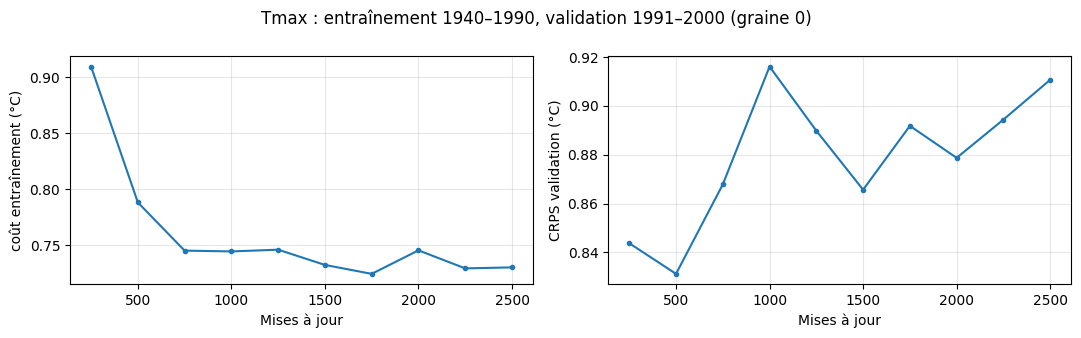

CRPS (°C)  twCRPS (°C)  Couverture 90 %  Largeur 90 % (°C)
Variable Modèle                                                            
Tmax     D1          1.701        0.696             0.84              7.586
         D2          1.707        0.700             0.80              7.500
         D3          1.646        0.684             0.88              7.755
         D4          1.652        0.687             0.88              7.678
         Bayes       1.574        0.692             0.80              6.665
Tmin     D1          1.042        0.167             0.96              7.379
         D2          1.025        0.163             0.96              7.488
         D3          0.992        0.154             1.00              7.555
         D4          0.983        0.151             1.00              7.655
         Bayes       0.972        0.138             0.96              6.808

In [13]:
PAS = {'max': {'D1': 1250, 'D2': 750}, 'min': {'D1': 1500, 'D2': 1250}}

# Observation de l'apprentissage, sans utiliser les températures 2001–2025.
train_courbe = (y['annee'] <= 1990).to_numpy()
val_courbe = y['annee'].between(1991, 2000).to_numpy()
exemple = entrainer_diffusion(x[train_courbe], y['max'].to_numpy()[train_courbe], 2500,
                            validation=(x[val_courbe], y['max'].to_numpy()[val_courbe]))
h = exemple['historique']
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, colonne in zip(axes, ['coût entraînement (°C)', 'CRPS validation (°C)']):
    ax.plot(h['pas'], h[colonne], 'o-', ms=3)
    ax.set(xlabel='Mises à jour', ylabel=colonne)
fig.suptitle('Tmax : entraînement 1940–1990, validation 1991–2000 (graine 0)')
plt.tight_layout()
plt.show()

# Réajustements sur 1940–2000, avec les durées déjà fixées.
suites_test = {}
for var in ['max', 'min']:
    for nom, poids in [('D1', 0.0), ('D2', 0.5)]:
        suites_test[var, nom] = entrainer_suite(x[avant], y[var].to_numpy()[avant], PAS[var][nom], var, poids)

def indicateurs(tirages, obs, seuil, variable):
    v = np.maximum if variable == 'max' else np.minimum
    q5, q95 = np.percentile(tirages, [5, 95], axis=0)
    return {'CRPS (°C)': crps(tirages, obs),
            'twCRPS (°C)': crps(v(tirages, seuil), v(obs, seuil)),
            'Couverture 90 %': np.mean((obs >= q5) & (obs <= q95)),
            'Largeur 90 % (°C)': np.mean(q95 - q5)}

predictions_test, lignes = {}, []
for var in ['max', 'min']:
    obs = y[var].to_numpy()[apres]
    seuil = np.quantile(y[var].to_numpy()[avant], 0.8 if var == 'max' else 0.2)
    for nom, parent, boot in [('D1', 'D1', False), ('D2', 'D2', False),
                              ('D3', 'D1', True), ('D4', 'D2', True)]:
        tirages = tirer_diffusion(suites_test[var, parent], x[apres], bootstrap=boot)
        predictions_test[var, nom] = tirages
        lignes.append({'Variable': 'T' + var, 'Modèle': nom, **indicateurs(tirages, obs, seuil, var)})
    bayes = tirer(ajuster(x[avant], y[var].to_numpy()[avant]), x[apres])
    predictions_test[var, 'Bayes'] = bayes
    lignes.append({'Variable': 'T' + var, 'Modèle': 'Bayes', **indicateurs(bayes, obs, seuil, var)})

scores_execution = pd.DataFrame(lignes).set_index(['Variable', 'Modèle'])
display(scores_execution.round(3))

**Commentaire.** Le coût d'entraînement baisse, mais le CRPS de validation remonte après environ
500 mises à jour : entraîner plus longtemps n'améliore pas forcément les prédictions. Ces deux scores
correspondent à des tâches différentes, débruitage et génération depuis un bruit pur.

Pour Tmax, le bootstrap améliore le CRPS d'environ 1,70 à 1,65 °C. La pondération des extrêmes apporte peu
ici. Bayes garde le meilleur CRPS global test ; les écarts restent à interpréter avec seulement 25 années.

## Projections jusqu'en 2100 : régression bayésienne et diffusion

La régression bayésienne et la diffusion sont réajustées sur **1940–2025**. Pour la diffusion, on conserve
les variantes retenues sur validation : D3 pour Tmax et D1 pour Tmin. Chaque méthode génère
10 000 trajectoires de 2026 à 2100 pour chacun des trois scénarios.
Les traits montrent les médianes et les bandes les quantiles 5 % et 95 % des températures annuelles.

Dans une trajectoire de diffusion, on conserve le même réseau et, pour D3, la même droite ; les innovations
annuelles sont indépendantes. Pour Bayes, on conserve le même triplet $(a,b,\sigma)$ et on renouvelle le bruit
chaque année. Le risque cumulé « au moins une fois » dépend de cette hypothèse de dépendance temporelle.
Les bandes sont des intervalles prédictifs annuels : ce ne sont pas des intervalles sur la seule tendance moyenne.

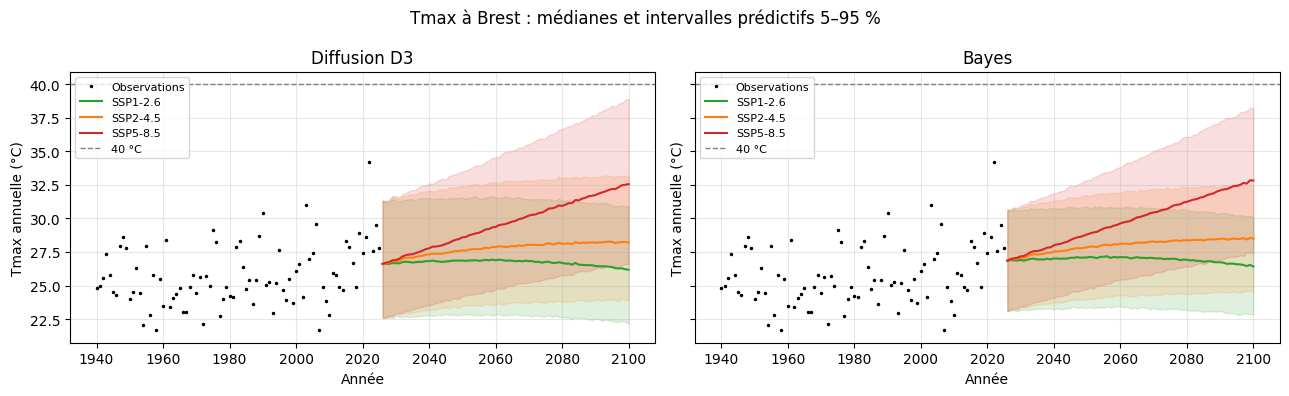

In [14]:
futur = yearly_future_co2.copy()
futur['annee'] = pd.to_datetime(futur['valid_time']).dt.year
SSP = {'ssp1-2.6': 'tab:green', 'ssp2-4.5': 'tab:orange', 'ssp5-8.5': 'tab:red'}

# Les 3 réseaux de chaque variable sont réellement réentraînés sur les 86 années.
suites_futur = {var: entrainer_suite(x, y[var].to_numpy(), PAS[var]['D1'], var) for var in ['max', 'min']}

def projeter(var):
    m = ajuster(x, y[var].to_numpy())
    return {s: tirer(m, np.log(futur[s].to_numpy())) for s in SSP}

def projeter_diffusion(var):
    # Une même graine entre scénarios garde les mêmes hasards : seul le CO₂ change.
    return {s: tirer_diffusion(suites_futur[var], np.log(futur[s].to_numpy()), bootstrap=(var == 'max'))
            for s in SSP}

def tracer(var, comparaisons, seuil):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
    for ax, (nom, sims) in zip(axes, comparaisons.items()):
        ax.plot(y['annee'], y[var], 'k.', ms=3, label='Observations')
        for s, couleur in SSP.items():
            q5, q50, q95 = np.percentile(sims[s], [5, 50, 95], axis=0)
            ax.fill_between(futur['annee'], q5, q95, color=couleur, alpha=0.15)
            ax.plot(futur['annee'], q50, color=couleur, label=s.upper())
        ax.axhline(seuil, color='grey', ls='--', lw=1, label=f'{seuil} °C')
        ax.set(title=nom, xlabel='Année', ylabel=f'T{var} annuelle (°C)')
        ax.legend(fontsize=8)
    fig.suptitle(f'T{var} à Brest : médianes et intervalles prédictifs 5–95 %')
    plt.tight_layout()
    plt.show()

sims_max = projeter('max')
sims_diffusion = projeter_diffusion('max')
tracer('max', {'Diffusion D3': sims_diffusion, 'Bayes': sims_max}, 40)

**Commentaire.** Les deux méthodes donnent des médianes qui montent avec le CO₂ et des trajectoires proches pour
un même scénario. Les trois scénarios se séparent progressivement : la concentration redescend à 400 ppm avec
SSP1-2.6, atteint 527 ppm avec SSP2-4.5 et 946 ppm avec SSP5-8.5 en 2100. Les valeurs historiques ne dépassaient
pas 428 ppm : le dernier scénario demande donc une forte extrapolation.

Les bandes de D3 incluent la variabilité annuelle apprise et l'incertitude sur la droite. Celles de Bayes incluent
la variabilité gaussienne et l'incertitude sur ses paramètres. Leur largeur ne mesure pas les erreurs possibles
sur les hypothèses communes : ancre logarithmique, rôle du seul CO₂ et distribution résiduelle stable.

Based on your probabilistic predictions, provide the distribution of the maximum annual temperature in 2100 for the three climate scenarios (SSPs). Based on your predictions, what is the probability of exceeding 40°C in Brest, by 2100, for the three climate scenarios?

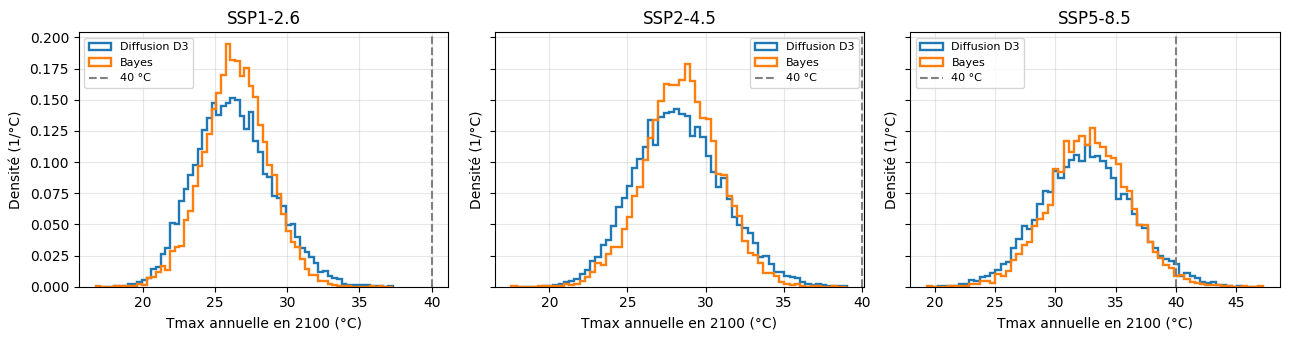

q5 (°C)  Médiane (°C)  q95 (°C)  P en 2100 (%)  \
Modèle       Scénario                                                   
Diffusion D3 SSP1-2.6   22.161        26.183    30.895           0.00   
             SSP2-4.5   23.893        28.200    33.135           0.00   
             SSP5-8.5   26.613        32.551    38.886           2.61   
Bayes        SSP1-2.6   22.832        26.420    30.072           0.00   
             SSP2-4.5   24.526        28.493    32.375           0.00   
             SSP5-8.5   27.416        32.820    38.208           1.53   

                       P au moins une fois (%)  Tirages en 2100 / 10 000  
Modèle       Scénario                                                     
Diffusion D3 SSP1-2.6                     0.00                         0  
             SSP2-4.5                     0.15                         0  
             SSP5-8.5                    17.22                       261  
Bayes        SSP1-2.6                     0.00                         0  
             SSP2-4.5                     0.00                         0  
             SSP5-8.5                     8.14                       153

0 dépassement / 10,000 tirages : borne supérieure Monte-Carlo à 95 % ≈ 0.030 %, pour ce modèle.


In [15]:
def resume_2100(comparaisons, seuil, au_dessus=True):
    lignes = []
    for nom, sims in comparaisons.items():
        for s, t in sims.items():
            depasse = t > seuil if au_dessus else t < seuil
            n = len(t)
            k_an, k_cum = int(depasse[:, -1].sum()), int(depasse.any(axis=1).sum())
            q5, med, q95 = np.percentile(t[:, -1], [5, 50, 95])
            lignes.append({'Modèle': nom, 'Scénario': s.upper(),
                           'q5 (°C)': q5, 'Médiane (°C)': med, 'q95 (°C)': q95,
                           'P en 2100 (%)': 100 * k_an / n,
                           'P au moins une fois (%)': 100 * k_cum / n,
                           'Tirages en 2100 / 10 000': k_an})
    return pd.DataFrame(lignes).set_index(['Modèle', 'Scénario'])

def comparer_distributions(var, comparaisons, seuil):
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
    for ax, s in zip(axes, SSP):
        valeurs = np.concatenate([sims[s][:, -1] for sims in comparaisons.values()])
        bins = np.linspace(valeurs.min(), valeurs.max(), 65)
        for nom, sims in comparaisons.items():
            ax.hist(sims[s][:, -1], bins=bins, density=True, histtype='step', lw=1.7, label=nom)
        ax.axvline(seuil, color='grey', ls='--', label=f'{seuil} °C')
        ax.set(title=s.upper(), xlabel=f'T{var} annuelle en 2100 (°C)', ylabel='Densité (1/°C)')
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

comparaisons_max = {'Diffusion D3': sims_diffusion, 'Bayes': sims_max}
comparer_distributions('max', comparaisons_max, 40)
resume_max = resume_2100(comparaisons_max, 40)
display(resume_max.round(3))

# À zéro dépassement, borne binomiale supérieure unilatérale à 95 % (erreur Monte-Carlo seule).
print(f'0 dépassement / {N:,} tirages : borne supérieure Monte-Carlo à 95 % ≈ '
      f'{100 * (1 - 0.05**(1 / N)):.3f} %, pour ce modèle.')

**Commentaire.** Sous SSP5-8.5, les médianes de D3 et Bayes sont proches : environ 32,6 et 32,8 °C dans cette
exécution. Pourtant, la probabilité de dépasser 40 °C en 2100 vaut environ 2,6 % avec D3 et 1,5 % avec Bayes.
Ce seuil se situe dans la queue droite : une différence de dispersion ou de forme de la loi peut beaucoup
changer la proportion de dépassements. La comparaison permet de voir cette sensibilité au modèle.

Le risque en 2100 concerne **une année**. Le risque « au moins une fois » concerne **75 années** : il est calculé
sur des trajectoires où les paramètres sont partagés dans le temps et les innovations annuelles sont indépendantes
conditionnellement à ces paramètres. Une autre dépendance entre années pourrait changer ce risque cumulé.
Sous SSP5-8.5, ce risque cumulé vaut environ 17,2 % avec D3 et 8,1 % avec Bayes dans cette exécution.

Un résultat de zéro dépassement n'est pas une probabilité physique nulle. Avec 10 000 tirages indépendants,
la borne binomiale supérieure à 95 % est d'environ 0,03 % pour le modèle simulé. Elle mesure seulement l'erreur
Monte-Carlo. L'incertitude liée au modèle et à l'extrapolation est beaucoup plus difficile à quantifier.
On n'a observé aucun Tmax supérieur à 34,2 °C dans ces données : le test historique ne valide pas directement
la queue à 40 °C en 2100.

Make the same study for the minimum annual temperatures in Brest. You can try a different approach to generate your predictions (without including the mathematical formulation).

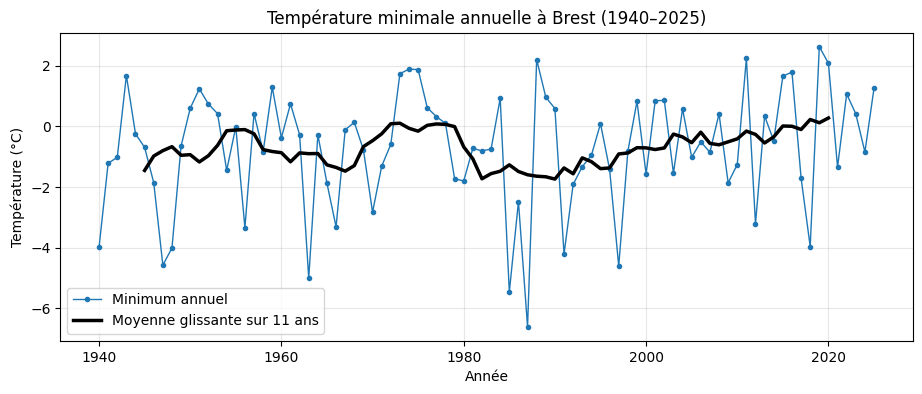

Corrélation Tmin / ln(CO₂) : 0.15


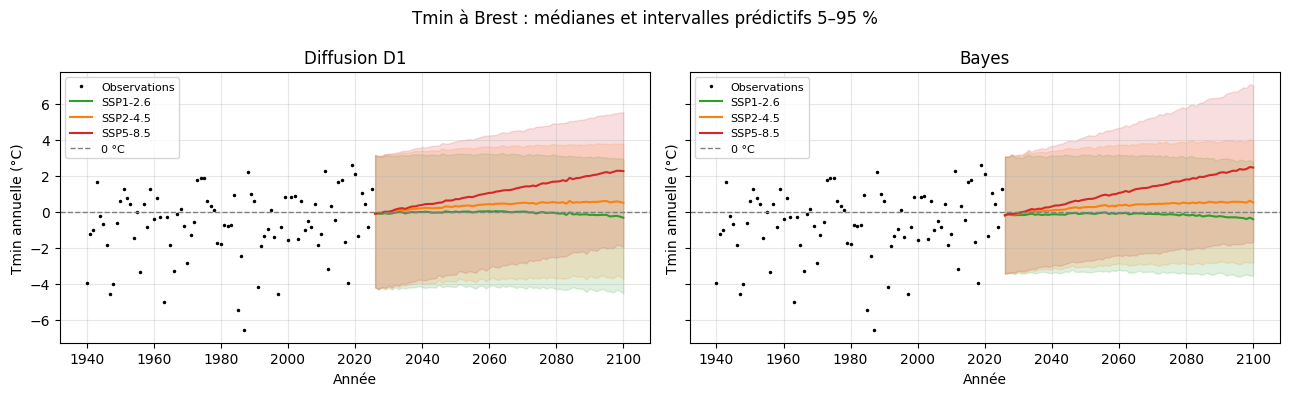

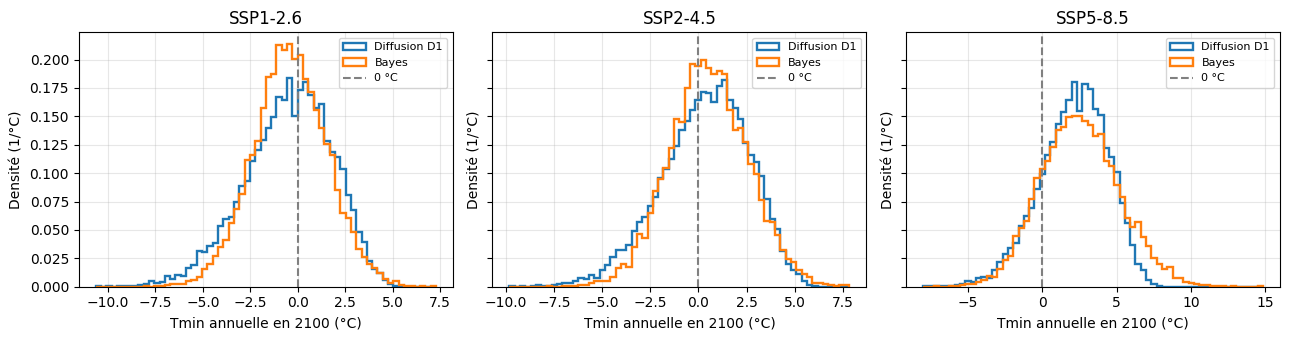

q5 (°C)  Médiane (°C)  q95 (°C)  P en 2100 (%)  \
Modèle       Scénario                                                   
Diffusion D1 SSP1-2.6   -4.558        -0.338     2.933          55.35   
             SSP2-4.5   -3.728         0.491     3.763          41.55   
             SSP5-8.5   -1.967         2.252     5.524          17.78   
Bayes        SSP1-2.6   -3.553        -0.424     2.762          58.63   
             SSP2-4.5   -2.824         0.507     3.931          40.02   
             SSP5-8.5   -1.676         2.451     7.014          17.14   

                       P au moins une fois (%)  Tirages en 2100 / 10 000  
Modèle       Scénario                                                     
Diffusion D1 SSP1-2.6                    100.0                      5535  
             SSP2-4.5                    100.0                      4155  
             SSP5-8.5                    100.0                      1778  
Bayes        SSP1-2.6                    100.0                      5863  
             SSP2-4.5                    100.0                      4002  
             SSP5-8.5                    100.0                      1714

Contrôle numérique des projections (bornes larges du protocole du groupe) :


,Variable,Modèle,Minimum brut (°C),Maximum brut (°C),Hors bornes de contrôle
0,Tmax,Diffusion D3,17.49,47.66,0
1,Tmax,Bayes,16.27,47.69,0
2,Tmin,Diffusion D1,-12.83,8.68,0
3,Tmin,Bayes,-11.00,14.84,0


In [16]:
plt.plot(y['annee'], y['min'], 'o-', ms=3, lw=1, color='tab:blue', label='Minimum annuel')
plt.plot(y['annee'], y['min'].rolling(11, center=True).mean(), lw=2.5, color='k',
         label='Moyenne glissante sur 11 ans')
plt.xlabel('Année')
plt.ylabel('Température (°C)')
plt.title('Température minimale annuelle à Brest (1940–2025)')
plt.legend()
plt.show()
print('Corrélation Tmin / ln(CO₂) :', round(np.corrcoef(y['min'], x)[0, 1], 2))

sims_min = projeter('min')
sims_min_diffusion = projeter_diffusion('min')
comparaisons_min = {'Diffusion D1': sims_min_diffusion, 'Bayes': sims_min}
tracer('min', comparaisons_min, 0)
comparer_distributions('min', comparaisons_min, 0)
resume_min = resume_2100(comparaisons_min, 0, au_dessus=False)
display(resume_min.round(3))

# Contrôle des tirages bruts, avant toute interprétation des probabilités.
controles = []
for variable, comparaisons, bornes in [('Tmax', comparaisons_max, (0, 50)),
                                      ('Tmin', comparaisons_min, (-30, 20))]:
    for nom, sims in comparaisons.items():
        t = np.concatenate(list(sims.values()), axis=1)
        assert np.isfinite(t).all(), 'Température simulée non finie'
        controles.append({'Variable': variable, 'Modèle': nom, 'Minimum brut (°C)': t.min(),
                          'Maximum brut (°C)': t.max(),
                          'Hors bornes de contrôle': int(((t < bornes[0]) | (t > bornes[1])).sum())})
print('Contrôle numérique des projections (bornes larges du protocole du groupe) :')
display(pd.DataFrame(controles).round(2))

**Approche et commentaire.** On reprend les étapes pour Tmin avec D1, retenu sur validation, et Bayes comme
comparaison. Le seuil choisi est **0 °C**, pour décrire les années avec gel. Il ne s'agit pas du nombre de jours
de gel : une seule journée négative suffit à rendre le minimum annuel négatif.

Sur 1940–2025, le minimum annuel est négatif 52 années sur 86. Il varie de −6,6 °C en 1987 à 2,6 °C en 2019.
Le lien avec le CO₂ est plus faible que pour Tmax, avec une corrélation d'environ 0,15. La moyenne sur 11 ans
reste proche de −0,7 °C jusque vers 2000, puis remonte. Les différences entre années sont importantes.

Dans les projections, les minima remontent avec le CO₂ et la probabilité de gel en 2100 diminue. Un résultat
proche de 100 % dans la colonne « au moins une fois » signifie que presque toutes les trajectoires simulées
contiennent une année avec gel entre 2026 et 2100 ; il ne signifie pas qu'il gèlera chaque année.
La faible relation historique et les hypothèses sur l'évolution de la dispersion limitent ces projections.

Sous SSP5-8.5, D1 et Bayes donnent une probabilité de gel en 2100 d'environ 18 % et 17 %. Leurs intervalles
diffèrent toutefois : D1 conserve une ancre fixe et une dispersion résiduelle stable, donc sa bande garde une
largeur presque constante. Bayes inclut l'incertitude sur la pente et sa bande s'élargit. D1 était préférable
sur la validation historique ; cela ne garantit pas qu'il représente toute l'incertitude d'une extrapolation à 2100.

# Conclusion

À Brest, le cycle saisonnier est modéré par rapport aux variations que peut connaître une région continentale.
Avec le seuil saisonnier retenu, on identifie 421 vagues de chaleur d'au moins trois jours. Leur fréquence augmente
nettement sur les dernières décennies ; la plus intense de la période est celle de juillet 2022.

Pour les extrêmes annuels, la régression bayésienne représente l'incertitude sur la droite et sur la variabilité
annuelle. Elle obtient le meilleur CRPS global observé sur le test parmi les méthodes principales comparées,
avec une formulation parcimonieuse. La diffusion apprend la distribution des fluctuations à partir de données
bruitées. L'ajout de l'incertitude sur la tendance apporte davantage que la pondération des extrêmes dans nos
expériences Tmax. Le protocole de validation retient D3 pour Tmax et D1 pour Tmin. Ces classements différents
montrent que les conclusions dépendent des années évaluées ; ils ne prouvent pas la supériorité générale d'une méthode.

En 2100, les deux approches prévoient des maxima plus élevés sous SSP5-8.5 et des minima moins souvent négatifs.
Elles peuvent donner des médianes proches et des risques de dépassement sensiblement différents. Les probabilités
à 40 °C dépendent d'une extrapolation très au-delà des observations et du choix de la distribution résiduelle.
Les 10 000 simulations rendent les calculs Monte-Carlo précis ; elles ne suppriment pas cette incertitude.